                 Open   High        Low      Close    Volume  Adj Close
Date                                                                   
2010-06-29  19.000000  25.00  17.540001  23.889999  18766300  23.889999
2010-06-30  25.790001  30.42  23.299999  23.830000  17187100  23.830000
2010-07-01  25.000000  25.92  20.270000  21.959999   8218800  21.959999
2010-07-02  23.000000  23.10  18.709999  19.200001   5139800  19.200001
2010-07-06  20.000000  20.00  15.830000  16.110001   6866900  16.110001
              Open         High          Low        Close        Volume  \
count  1692.000000  1692.000000  1692.000000  1692.000000  1.692000e+03   
mean    132.441572   134.769698   129.996223   132.428658  4.270741e+06   
std      94.309923    95.694914    92.855227    94.313187  4.295971e+06   
min      16.139999    16.629999    14.980000    15.800000  1.185000e+05   
25%      30.000000    30.650000    29.215000    29.884999  1.194350e+06   
50%     156.334999   162.370002   153.150002  

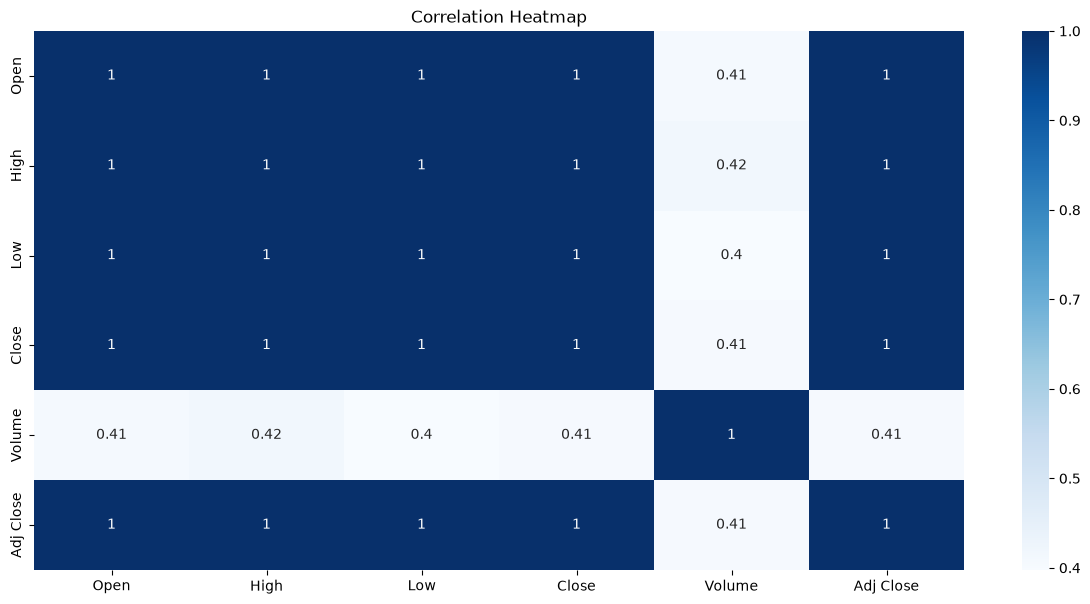

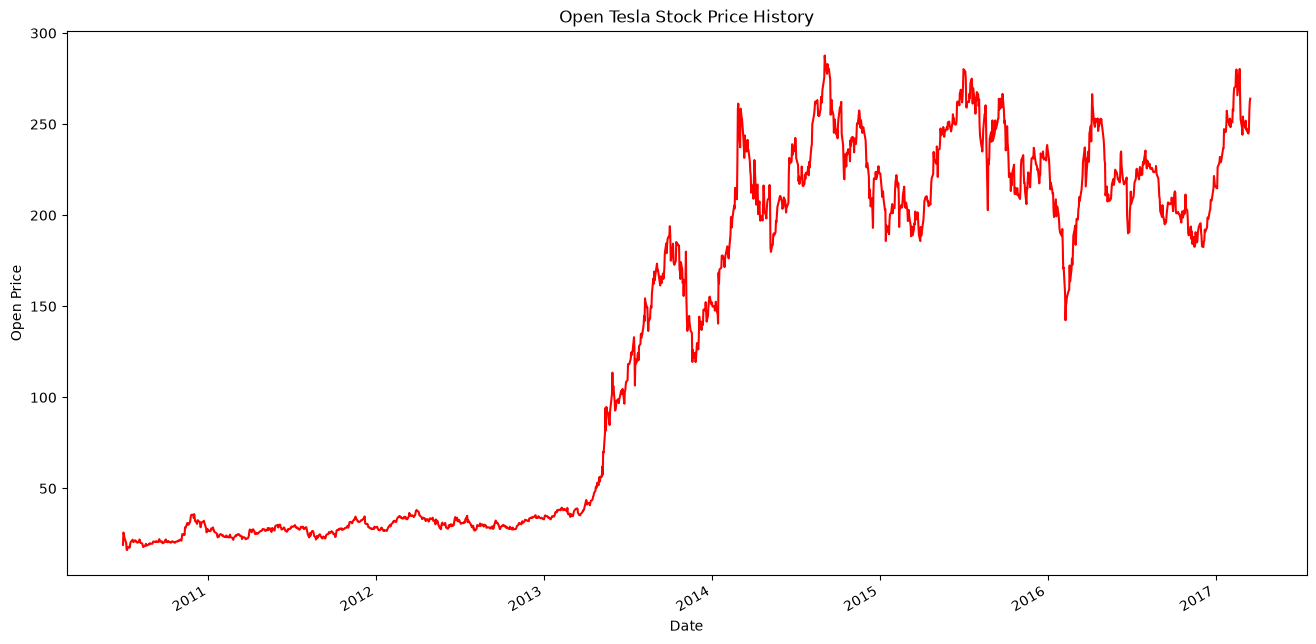

Missing Values:
Open         0
High         0
Low          0
Close        0
Volume       0
Adj Close    0
dtype: int64
Data Shape: (1692, 1)
Train Size: 1269
Test Size: 423
X Train Shape: (1209, 60, 1)
Y Train Shape: (1209,)


C:\Users\HP\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        29,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,465 (165.88 KB)

 Trainable params: 42,465 (165.88 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 10s 149ms/step - loss: 0.0102 - mean_squared_error: 0.0102 - val_loss: 0.0102 - val_mean_squared_error: 0.0102
Epoch 2/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - loss: 0.0146 - mean_squared_error: 0.0146 - val_loss: 0.0041 - val_mean_squared_error: 0.0041
Epoch 3/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - loss: 0.0232 - mean_squared_error: 0.0232 - val_loss: 0.0142 - val_mean_squared_error: 0.0142
Epoch 4/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - loss: 0.0264 - mean_squared_error: 0.0264 - val_loss: 0.0275 - val_mean_squared_error: 0.0275
Epoch 5/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step - loss: 0.0154 - mean_squared_error: 0.0154 - val_loss: 0.0195 - val_mean_squared_error: 0.0195
Epoch 6/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - loss: 0.0053 - mean_squared_error: 0.0053 - val_loss: 0.0024 - val_mean_squared_error: 0.0024
Epoch 7/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step - loss: 0.0047 - mean_squared_error: 0.0047 - val_loss: 0.

In [ ]:

# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import math
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error


# ==========================================
# 2. LOAD DATASET
# ==========================================

df = pd.read_csv(r"C:\Users\HP\Downloads\Tesla.csv", parse_dates=True, index_col="Date")

print(df.head())
print(df.describe())
print("Dataset Shape:", df.shape)

df.info()


# ==========================================
# 3. DATA VISUALIZATION
# ==========================================

plt.figure(figsize=(15, 7))
sns.heatmap(df.corr(numeric_only=True), cbar=True, annot=True, cmap='Blues')
plt.title("Correlation Heatmap")
plt.show()


df["Open"].plot(figsize=(16, 8), color='red')
plt.title("Open Tesla Stock Price History")
plt.xlabel("Date")
plt.ylabel("Open Price")
plt.show()


# ==========================================
# 4. CHECK MISSING VALUES
# ==========================================

print("Missing Values:")
print(df.isna().sum())


# ==========================================
# 5. SELECT OPEN PRICE
# ==========================================

dataset = df[["Open"]].copy()

data = dataset.values

print("Data Shape:", data.shape)


# ==========================================
# 6. TRAIN TEST SPLIT
# ==========================================

train_size = int(len(data) * 0.75)
test_size = len(data) - train_size

print("Train Size:", train_size)
print("Test Size:", test_size)


# ==========================================
# 7. DATA SCALING
# ==========================================

scaler = MinMaxScaler(feature_range=(0, 1))

# Fit scaler only on training data
scaler.fit(data[:train_size])

scaled_data = scaler.transform(data)


# ==========================================
# 8. CREATE TRAINING SEQUENCES
# ==========================================

train_data = scaled_data[:train_size, 0]

x_train = []
y_train = []

for i in range(60, len(train_data)):
    x_train.append(train_data[i-60:i])
    y_train.append(train_data[i])

x_train = np.array(x_train)
y_train = np.array(y_train)

x_train = np.reshape(
    x_train,
    (x_train.shape[0], x_train.shape[1], 1)
)

print("X Train Shape:", x_train.shape)
print("Y Train Shape:", y_train.shape)


# ==========================================
# 9. BUILD LSTM MODEL
# ==========================================

model = Sequential()

model.add(LSTM(50, return_sequences=True,
               input_shape=(x_train.shape[1], 1)))

model.add(LSTM(64, return_sequences=False))

model.add(Dense(32))
model.add(Dense(16))
model.add(Dense(1))

model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mean_squared_error']
)

model.summary()


# ==========================================
# 10. EARLY STOPPING
# ==========================================

callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True
    )
]


# ==========================================
# 11. TRAIN MODEL
# ==========================================

history = model.fit(
    x_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=callbacks
)


# ==========================================
# 12. TRAINING LOSS VISUALIZATION
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title("Model Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend(['Training Loss', 'Validation Loss'])
plt.show()


# ==========================================
# 13. CREATE TESTING SEQUENCES
# ==========================================

test_data = scaled_data[train_size-60:, 0]

x_test = []
y_test = []

for i in range(60, len(test_data)):
    x_test.append(test_data[i-60:i])
    y_test.append(test_data[i])

x_test = np.array(x_test)
y_test = np.array(y_test)

x_test = np.reshape(
    x_test,
    (x_test.shape[0], x_test.shape[1], 1)
)

print("X Test Shape:", x_test.shape)
print("Y Test Shape:", y_test.shape)


# ==========================================
# 14. MAKE PREDICTIONS
# ==========================================

predictions = model.predict(x_test)

# Convert scaled values into actual prices
predictions = scaler.inverse_transform(predictions)

y_test_inv = scaler.inverse_transform(
    y_test.reshape(-1, 1)
)


# ==========================================
# 15. MODEL EVALUATION
# ==========================================

mae = mean_absolute_error(y_test_inv, predictions)

mse = mean_squared_error(y_test_inv, predictions)

rmse = np.sqrt(mse)

print("Model Evaluation Results")
print("------------------------")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))


# ==========================================
# 16. ACTUAL VS PREDICTED GRAPH
# ==========================================

train = dataset.iloc[:train_size].copy()

test = dataset.iloc[train_size:].copy()

test['Predictions'] = predictions.flatten()

plt.figure(figsize=(16, 6))

plt.title('Tesla Open Stock Price Prediction', fontsize=18)

plt.xlabel('Date', fontsize=18)

plt.ylabel('Open Price', fontsize=18)

plt.plot(train['Open'], linewidth=2)

plt.plot(test['Open'], linewidth=2)

plt.plot(test['Predictions'], linewidth=2)

plt.legend(['Train', 'Actual Test', 'Predictions'])

plt.show()


# ==========================================
# 17. SAVE MODEL
# ==========================================

model.save("tesla_stock_model.keras")

print("Model saved successfully!")


# ==========================================
# 18. LOAD SAVED MODEL
# ==========================================

from tensorflow.keras.models import load_model

loaded_model = load_model("tesla_stock_model.keras")

print("Saved model loaded successfully!")
